## Practica Identificacion de sistemas. Tecnicas no parametricas

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as signal
import numpy as np


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



In [4]:
df=pd.read_csv('data.csv')
df.head()

,time,u,y
0,0.000758,73.051979,0.093873
1,0.010457,59.356608,1.213926
2,0.020310,77.842171,2.302655
3,0.030256,82.031419,3.413871
4,0.040137,83.181970,4.478697


In [5]:
time = df.time
u = df.u
y = df.y

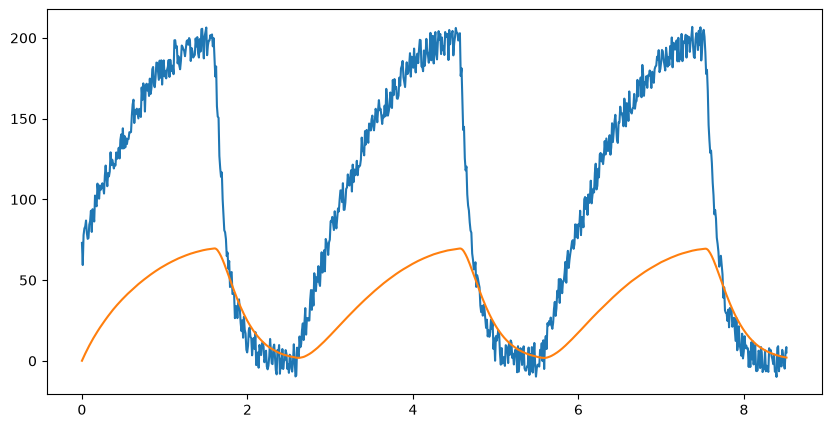

In [8]:
# inspeccion de datos
plt.figure(figsize=(10, 5))
plt.plot(time, u)
plt.plot(time, y)
plt.show()

In [ ]:
##Entrada y salida diferentes
#El sistema elimina el rizado y disminuye la amplitud de la señal de entrada, además de introducir un retardo en la señal de salida.
h_desc, _ =signal.desconvolve(y, u)
print(len(h_desc))

print(len(u))

##Zero padding Poner ceron del valor p-estimaciones
##

round(len(u) * 1/3)

AttributeError: module 'scipy.signal' has no attribute 'desconvolve'

In [ ]:
ypad = np.concatenate((y, np.zeros(round(len(u) * 1/3))))
h, _ = signal.deconvolve(ypad, u)
print(len(h))

plt.figure(figsize=(10, 5))
plt.plot(h) # Tarea Graficar con el tiempo
plt.title('Respuesta al impulso del sistema')
plt.show()

#Revision de la identificacion
#Recortar el vector de tiempo para que quede con el mismo tamaño del vector del tiempo.recortar la longitud del mas grande
y_pred_desc = signal.convolve(h, u)
plt.figure(figsize=(10, 5))
plt.plot(y_pred_desc, label='Predicha', color ='b')
plt.plot(y, label='Real', color ='r')
plt.legend()

#La salida predicha se calcula porque no tengo una referencia del sistema que esta, pero si del sistema predicho

##0,0.5,1, 1.5---Me dan el vector de tiempo y calculo el vector de tiempo 1-0.5 = 0.5, 1.5-1.0= 0.5 ts=0.5
